# Medyan kanal değerleri: RGB / HSV(Hue) / Lab / YCrCb

In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

PATHS = {"image": "011.png", "022": "022.png"}

libpng warning: iCCP: extra compressed data
libpng warning: iCCP: extra compressed data


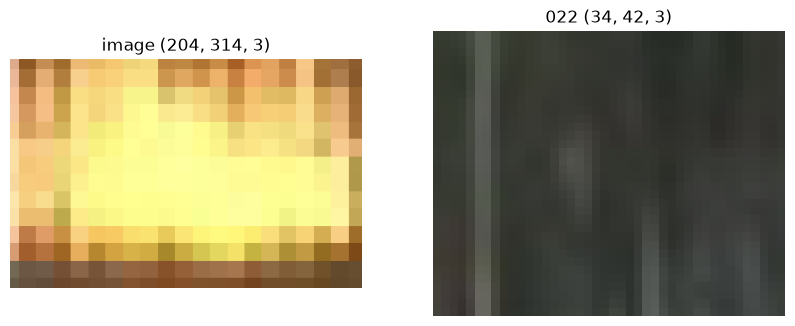

In [4]:
def load(path):
    img = cv2.imread(path, cv2.IMREAD_UNCHANGED)
    assert img is not None, f"bulunamadı: {path}"
    mask = None
    if img.ndim == 3 and img.shape[2] == 4:      # alpha varsa saydam pikselleri hariç tut
        mask = img[..., 3] > 0
        img = img[..., :3]
    return img, mask

imgs = {k: load(p) for k, p in PATHS.items()}

fig, axs = plt.subplots(1, len(imgs), figsize=(5 * len(imgs), 5))
for ax, (k, (img, _)) in zip(np.atleast_1d(axs), imgs.items()):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(f"{k} {img.shape}"); ax.axis("off")
plt.show()

In [5]:
SPACES = {
    "RGB":   (None,                    ["R", "G", "B"]),
    "HSV":   (cv2.COLOR_BGR2HSV,       ["H", "S", "V"]),
    "Lab":   (cv2.COLOR_BGR2LAB,       ["L", "a", "b"]),
    "YCrCb": (cv2.COLOR_BGR2YCrCb,     ["Y", "Cr", "Cb"]),
}

def medians(img, mask=None):
    out = {}
    for space, (code, names) in SPACES.items():
        if code is None:
            conv = img[..., ::-1]                      # BGR -> RGB
        else:
            conv = cv2.cvtColor(img, code)
        px = conv[mask] if mask is not None else conv.reshape(-1, 3)
        for n, v in zip(names, np.median(px, axis=0)):
            out[f"{space}.{n}"] = float(v)
    return out

res = {k: medians(*v) for k, v in imgs.items()}

keys = list(next(iter(res.values())).keys())
print(f"{'channel':<10}" + "".join(f"{k:>10}" for k in res))
for key in keys:
    print(f"{key:<10}" + "".join(f"{res[k][key]:>10.1f}" for k in res))

channel        image       022
RGB.R          245.0      55.0
RGB.G          208.0      57.0
RGB.B          123.0      50.0
HSV.H           22.0      42.0
HSV.S          125.0      25.0
HSV.V          245.0      57.0
Lab.L          217.0      60.0
Lab.a          128.0     126.0
Lab.b          176.0     131.0
YCrCb.Y        209.0      55.0
YCrCb.Cr       149.0     127.0
YCrCb.Cb        78.0     126.0


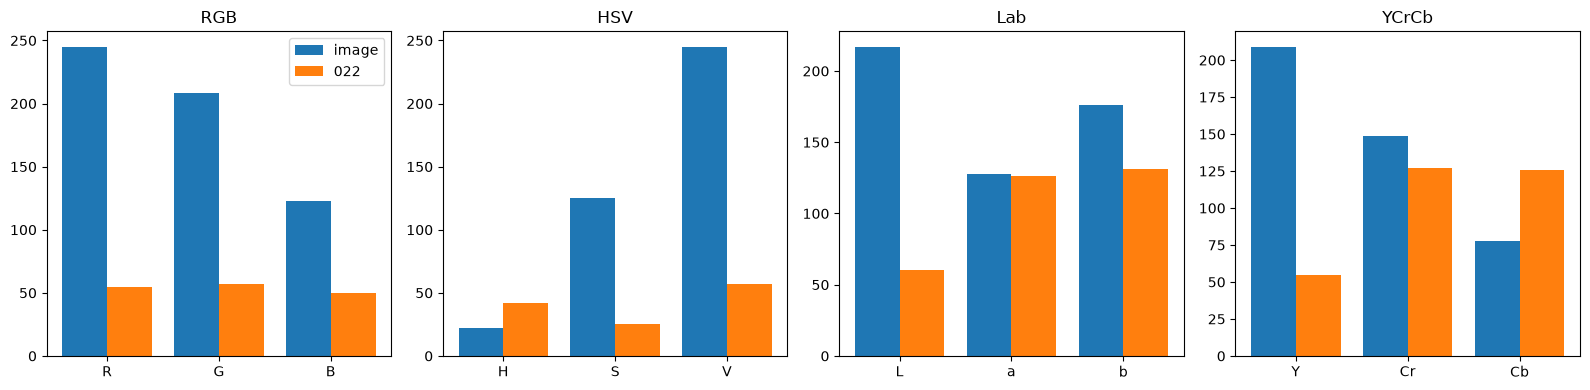

In [6]:
fig, axs = plt.subplots(1, len(SPACES), figsize=(4 * len(SPACES), 4))
w = 0.8 / len(res)
for ax, (space, (_, names)) in zip(axs, SPACES.items()):
    x = np.arange(len(names))
    for i, k in enumerate(res):
        ax.bar(x + i * w, [res[k][f"{space}.{n}"] for n in names], w, label=k)
    ax.set_xticks(x + w * (len(res) - 1) / 2); ax.set_xticklabels(names); ax.set_title(space)
axs[0].legend()
plt.tight_layout(); plt.show()